# Fitting template: $\Lambda$CDM background

Fits $P_{MG}/P_{GR}-1$ in three steps:
1. each $(c_K, c_B)$ spectrum with the template model $\to a, b, s$
2. each parameter linearly in $c_B$: $p = m(c_K)\, c_B + y_0(c_K)$
3. $m$ and $y_0$ averaged over $c_K$ (simple mean, error = scatter$/\sqrt{N}$)

Models (`MODEL`):
- `'tanh_kBkJ'`: $a \tanh\left[s\,\frac{\log_{10}(k/\sqrt{k_B k_J})}{\log_{10}(k_B/k_J)}\right] + b$
- `'tanh_kB'`: $a \tanh\left[2\log_{10}(s\,k/k_B)\right] + b$

Spectra computed with `scripts/compute_spectra.py` (`NAME = 'fit_LCDM'`).

In [1]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from hiclass_tools import load_spectra, fit_template, MODELS
from hiclass_tools.plotting import use_style, ColorScale

use_style(fontsize=12)

In [2]:
# Configuration
SPECTRA = 'fit_LCDM'
MODEL = 'tanh_kB'          # 'tanh_kBkJ' | 'tanh_kB'
K_MIN = None                 # lower k limit of the fit [h/Mpc] (None: whole range)

spectra = load_spectra(SPECTRA)
model = MODELS[MODEL]
cK, cB = spectra.cK, spectra.cB

print(f"Background: w0={spectra.w0}, wa={spectra.wa}")
print(f"cK: {len(spectra.cK)} values in [{spectra.cK[0]:.3g}, {spectra.cK[-1]:.3g}]")
print(f"cB: {len(spectra.cB)} values in [{spectra.cB[0]:.3g}, {spectra.cB[-1]:.3g}]")
print(f"k:  {len(spectra.k)} values in [{spectra.k[0]:.3g}, {spectra.k[-1]:.3g}] h/Mpc")
print(f"{len(spectra.pk_mg)} MG spectra, {len(spectra.failed)} failed in CLASS")

Background: w0=-1.0, wa=0.0
cK: 10 values in [1e+03, 1e+06]
cB: 10 values in [0.5, 1.5]
k:  100 values in [0.001, 10] h/Mpc
100 MG spectra, 0 failed in CLASS


In [3]:
tfit = fit_template(spectra, MODEL, k_min=K_MIN)
template = tfit.template

print(f"Mean error of the spectrum fits: {tfit.mean_error * 100:.2f} %")
for p in model.params:
    print(f"  {p}: mean R^2 of the linear cB fits = {tfit.mean_r2(p):.4f}")

Mean error of the spectrum fits: 3.55 %
  a: mean R^2 of the linear cB fits = 0.9988
  b: mean R^2 of the linear cB fits = 0.9988
  s: mean R^2 of the linear cB fits = 0.9432


In [4]:
# Colour scales
cb_colors = ColorScale(cB, 'Reds')
ck_colors = ColorScale(cK, 'Blues', log=True)
param_colors = ['b', 'm', 'g', 'y']

def ck_label(ck):
    n = np.log10(ck)
    return fr'$\mathbf{{c_K=10^{{{n:0.0f}}}}}$' if np.isclose(n, round(n)) else fr'$\mathbf{{c_K={ck:.2f}}}$'

## Step 1 and 2: spectrum fits and $c_B$ dependence

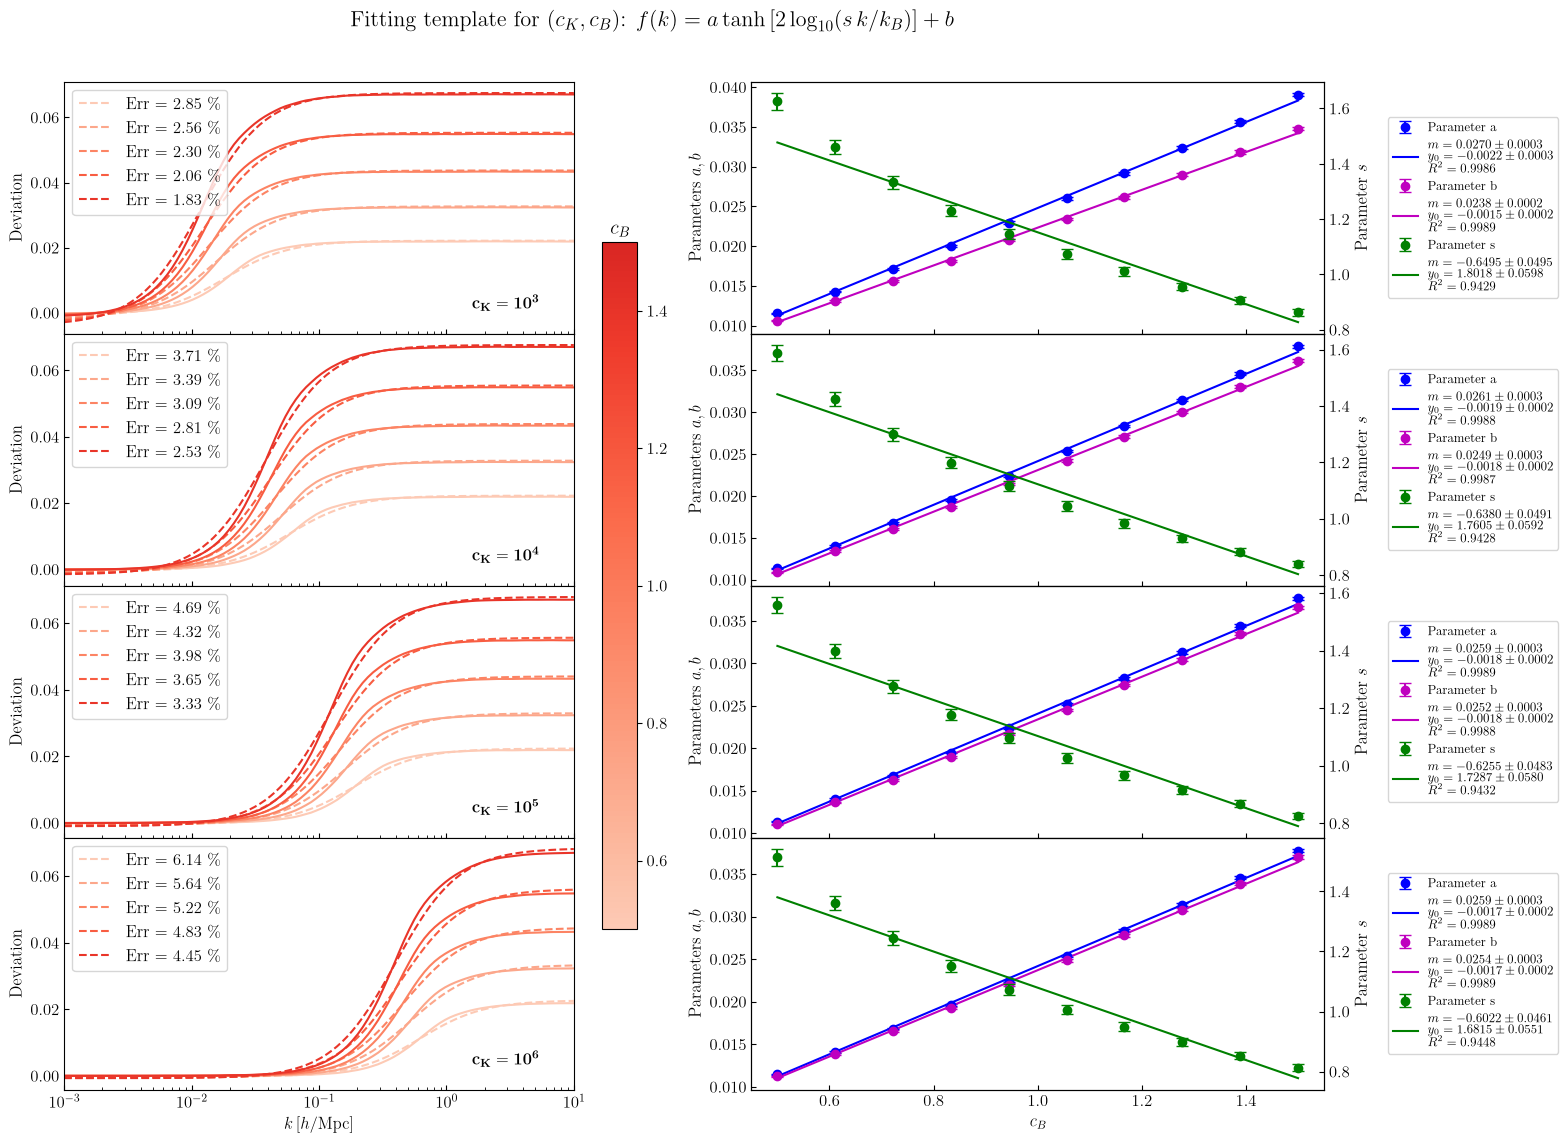

In [5]:
cK_red = tfit.cK[::3]
cB_red = cB[::2]
cb_line = np.linspace(cB[0], cB[-1], 50)

fig, axs = plt.subplots(len(cK_red), 2, figsize=(14, 3*len(cK_red)), sharex='col', squeeze=False)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.08, top=0.92, hspace=0)

for i, ck in enumerate(cK_red):
    for cb in cB_red:
        fit = tfit.spectrum_fits.get((ck, cb))
        if fit is None:
            continue
        axs[i,0].semilogx(fit.k, fit.y, color=cb_colors(cb))
        axs[i,0].plot(fit.k, fit.y_fit, color=cb_colors(cb), linestyle='--',
                      label=fr"Err = {fit.err * 100:0.2f} \%")

    axs[i,0].text(0.80, 0.1, ck_label(ck), transform=axs[i,0].transAxes)
    axs[i,0].legend(loc='upper left')
    axs[i,0].set_ylabel('Deviation')

    # Parameters vs cB: s on its own scale (right axis)
    ax_s = axs[i,1].twinx()
    handles = []
    for p, color in zip(model.params, param_colors):
        ax = ax_s if p == 's' else axs[i,1]
        line = tfit.cb_fits[ck][p]
        h_data = ax.errorbar(line.x, line.values, yerr=line.sigma, color=color, fmt='o', capsize=4,
                             label=f'Parameter {p}')
        h_fit, = ax.plot(cb_line, line(cb_line), color=color,
                         label=(fr"$m={line.m:.4f} \pm {line.m_err:.4f}$" + '\n' +
                                fr"$y_0={line.y0:.4f} \pm {line.y0_err:.4f}$" + '\n' +
                                fr"$R^2={line.r2:.4f}$"))
        handles.extend([h_data, h_fit])
    axs[i,1].legend(handles=handles, loc='center left', bbox_to_anchor=(1.1, 0.5), fontsize=9)
    axs[i,1].set_ylabel(r'Parameters $a, b$')
    ax_s.set_ylabel(r'Parameter $s$')
    ax_s.tick_params(axis='y', which='both', direction='in')

axs[-1,0].set_xlim([spectra.k[0], spectra.k[-1]])
axs[-1,0].set_xlabel(r"$k\,[h/\mathrm{Mpc}]$")
axs[-1,1].set_xlabel(r'$c_B$')
fig.suptitle(fr"Fitting template for $(c_K,c_B)$: $f(k) = {model.latex}$", fontsize=16)

cbar = plt.colorbar(cb_colors.mappable, ax=list(axs[:,0]), fraction=0.06, shrink=1.5)
cbar.ax.set_title(r"$c_B$")

for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

## Step 3: $m$ and $y_0$ as a function of $c_K$

Text(0.5, 0.98, 'Linear-fit parameters as a function of $c_K$')

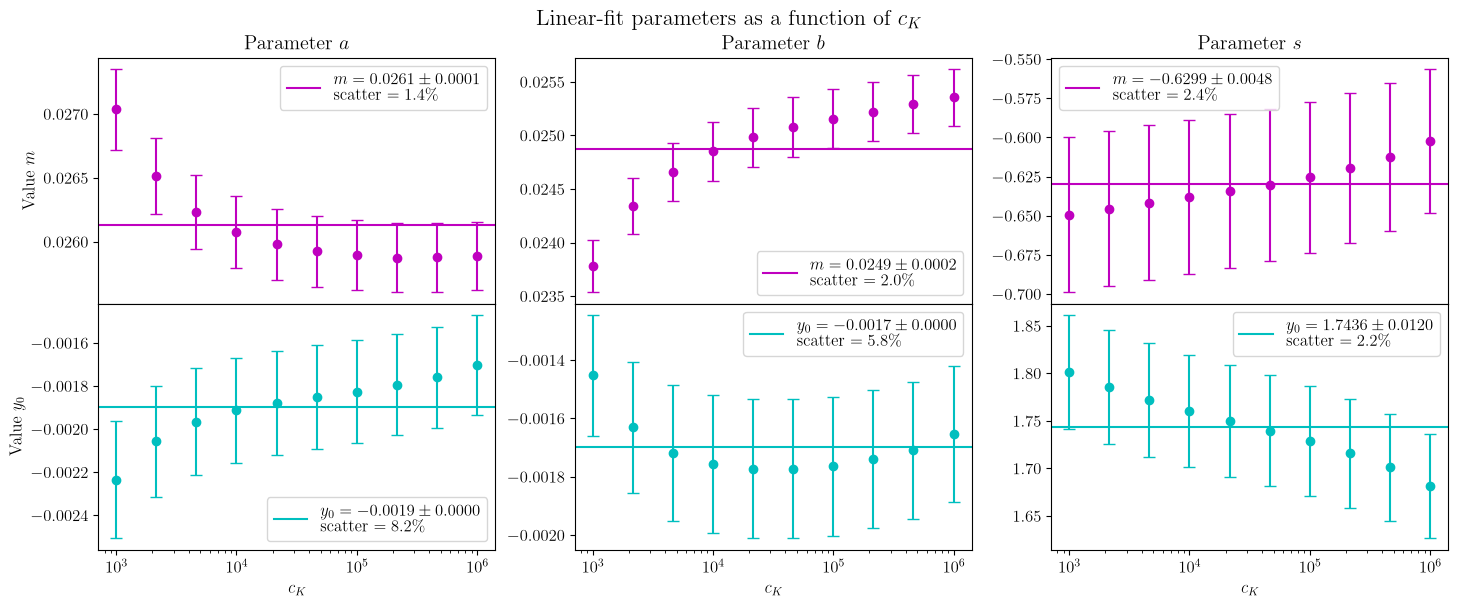

In [6]:
fig, axs = plt.subplots(2, len(model.params), figsize=(5*len(model.params), 6), sharex=True, squeeze=False)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.08, top=0.9, hspace=0)

for j, p in enumerate(model.params):
    for i, (q, q_label, color) in enumerate([('m', 'm', 'm'), ('y0', 'y_0', 'c')]):
        mean = tfit.ck_fits[p][q]
        axs[i,j].errorbar(mean.x, mean.values, yerr=mean.sigma, c=color, fmt='o', capsize=4)
        axs[i,j].axhline(mean.value, color=color,
                         label=(fr"${q_label}={mean.value:.4f} \pm {mean.error:.4f}$" + '\n' +
                                fr"scatter $= {100 * mean.rel_scatter:.1f}\%$"))
        axs[i,j].legend()

    axs[0,j].set_title(fr'Parameter ${p}$')
    axs[1,j].set_xlabel(r'$c_K$')

axs[0,0].set_xscale('log')
axs[0,0].set_ylabel('Value $m$')
axs[1,0].set_ylabel(r'Value $y_0$')
fig.suptitle(r'Linear-fit parameters as a function of $c_K$', fontsize=16)

## Template error

Text(0.5, 1.0, '$c_K$')

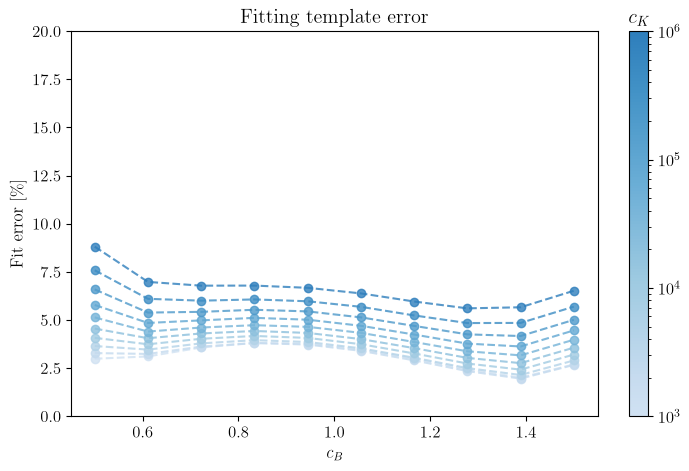

In [9]:
errors = template.errors(spectra, k_min=K_MIN)   # {(ck, cb): relative error} for k >= K_MIN

fig, ax = plt.subplots(figsize=(8, 5))
for ck in cK:
    err_values = [errors[(ck, cb)] * 100 for cb in spectra.cB_for(ck)]
    ax.plot(spectra.cB_for(ck), err_values, marker='o', linestyle='--', color=ck_colors(ck), alpha=0.8)

ax.set_xlabel(r'$c_B$')
ax.set_ylabel(r'Fit error [\%]')
ax.set_title('Fitting template error')
ax.set_ylim([0, 20])

cbar = plt.colorbar(ck_colors.mappable, ax=ax, fraction=0.1, shrink=1)
cbar.ax.set_title(r"$c_K$")

In [8]:
# Save the template (data/templates/<name>.pkl). Load it later with Template.load(name)
template.save(f'{SPECTRA}_{MODEL}')
template.coefficients

{'a': {'m': (0.026129347668478593, 0.00011968250120019994),
  'y0': (-0.0018979128633169564, 4.9450713298676434e-05)},
 'b': {'m': (0.02487182245761951, 0.00015624598606617796),
  'y0': (-0.0016967656210409763, 3.1224555305579166e-05)},
 's': {'m': (-0.6298623623649827, 0.004768554800967102),
  'y0': (1.7436307973126948, 0.011988634632205383)}}